In [1]:
import os
mactex_path = "/Library/TeX/texbin"
if mactex_path not in os.environ["PATH"]:
    os.environ["PATH"] += os.pathsep + mactex_path

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pde import PDE, FieldCollection, MemoryStorage, PolarSymGrid, ScalarField, PDEBase
from pde.backends import get_backend
import pandas as pd
# Enable full LaTeX rendering
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif"
})
%load_ext autoreload
%autoreload 2
pd.set_option("display.max_rows", 200)

In [90]:
def merge_presets(presets, defaults):
    """Merge each preset dict with defaults; preset values take priority."""
    return {name: {**defaults, **preset} for name, preset in presets.items()}

integration_dict = {
    'outer_radius': 60,
    'num_pts_radius': 1000,
    't_max': 100,
    'dt': .001,
}
seed_dict = {
    'N_init': 100,
    'seed_radius': 10,
    'gaussian_sharpness': 2,
    'wave_cutoff': .01,
    'init_method': 'gaussian'#'cosine_taper'
}
analysis_dict = {
    'wavefront_method':'effective_carrying_capacity',
    'wavefront_cutoff':.1,
    'tracker_time':.2,
}
default_config = {
    'r': 0.5,
    'K': 50,
    'D': 0.35,
    'a': 0.03,
    'm0': 0.25,
    'h': 0.05,
    'b_r': 0.015,
    'b_k': 0.015,
    'escape': 0.5,
    'E_r0': 0.05,
    'E_k0': 0.05,
}
preset_dicts = {
    'baseline': {
        'description': 'default config'
    },

    'high motility + weak niche': {
    'description': 'High growth and high motility. Rapid front propagation with weak immune containment.',
    'r':.95,
    'D':.9,
    'h':.1,
    'b_r':.005,
    'b_k':.005,
    'escape':.75,
},
'high predation/immune pressure':
{
    'description':'Strong immune attack, low escape. The lesion struggles to establish and may regress.',
    'm0':.4,
    'a':.2,
    'h':.02,
    'b_r':.01,
    'b_k':.01,
    'escape':.1,
},
'strong niche construction':
{
    'description':'Strong ecological engineering. Niche construction quickly suppresses immune pressure and lifts carrying capacity.',
    'r':.13,
    'D':.15,
    'h':.04,
    'b_r':.1,
    'b_k':.1,
}
}
bcs = {"derivative":0}
merged_presets = merge_presets(preset_dicts, default_config)
config_dict = {'integration': integration_dict, 'seed':seed_dict,'bcs':bcs,'presets': merged_presets, 'analysis':analysis_dict}


def rolling_area(u_init, r_coords):
    """Cumulative area (polar coordinates) of u_init up to each radius."""
    dr = np.gradient(r_coords)
    return np.cumsum(2 * np.pi * r_coords * u_init * dr)

def compute_wavefront_idx_by_height(u_curr, r_coords, cutoff,e_field):
    cutoff_idx = np.flatnonzero(u_curr <= cutoff * np.max(u_curr))
    if cutoff_idx.size:
        return cutoff_idx[0]
    return -1

def compute_wavefront_idx_by_area(u_curr, r_coords, cutoff,e_field):
    roll = rolling_area(u_curr, r_coords)
    total = roll[-1]
    cutoff_idx = np.flatnonzero(roll > (1-cutoff )* total)
    if cutoff_idx.size:
        return cutoff_idx[0]
    return -1

def compute_wavefront_idx_by_carrying_capacity(u_curr, r_coords, cutoff,e_field):
    cutoff_idx = np.flatnonzero(u_curr <= cutoff * default_config['K'])
    if cutoff_idx.size:
        return cutoff_idx[0]
    return -1

def compute_wavefront_idx_by_effective_carrying_capacity(u_curr, r_coords, cutoff,e_field):
    threshold = cutoff * default_config['K'] * e_field
    post_cutoff_idx = np.flatnonzero(u_curr < threshold)[0]
    if post_cutoff_idx == 0:
        return r_coords[0], 0
    prev_cutoff_idx = post_cutoff_idx - 1
    r_val = r_coords[prev_cutoff_idx] + ((r_coords[post_cutoff_idx]-r_coords[prev_cutoff_idx])*(threshold[post_cutoff_idx] - u_curr[prev_cutoff_idx])/(u_curr[post_cutoff_idx]-u_curr[prev_cutoff_idx]))
    return r_val, post_cutoff_idx

def compute_wavefront_idx_by_effective_carrying_capacity_area(u_curr, r_coords, cutoff,e_field):
    roll = rolling_area(u_curr/(default_config['K']*e_field),r_coords)
    total = roll[-1]
    cutoff_idx = np.flatnonzero(roll > (1-cutoff)*total)
    if cutoff_idx.size:
        return cutoff_idx[0]
    return -1

def compute_wavefront_idx(config,u_curr, r_coords,e_field):
    method_dispatch = {'height':compute_wavefront_idx_by_height, 'area':compute_wavefront_idx_by_area, 'carrying_capacity':compute_wavefront_idx_by_carrying_capacity,'effective_carrying_capacity':compute_wavefront_idx_by_effective_carrying_capacity,'effective_carrying_capacity_area':compute_wavefront_idx_by_effective_carrying_capacity_area}
    chosen_method =method_dispatch.get(config['wavefront_method'])
    return chosen_method(u_curr, r_coords, config['wavefront_cutoff'], e_field)

def compute_participation_area(u_curr):
    total_mass = u_curr.integral
    squared_mass = (u_curr**2).integral
    effective_area = (total_mass**2) / squared_mass
    return effective_area


def build_initial_N(config):
    seed_params = config['seed']
    integration_params= config['integration']
    grid = PolarSymGrid(radius=integration_params['outer_radius'], shape = integration_params['num_pts_radius'])
    r_coords = grid.axes_coords[0]

    def super_gaussian():
        exponent = 2*seed_params['gaussian_sharpness']
        u_init = np.exp(-(r_coords/seed_params['seed_radius'])**exponent)
        cutoff_idx = compute_wavefront_idx_by_height(u_init,r_coords,seed_params['wave_cutoff'])
        u_init[cutoff_idx + 1:] = 0
        return u_init

    def cosine_taper():
        u_init = 1 - (r_coords/seed_params['seed_radius'])
        u_init[u_init < 0] = 0
        return u_init

    def super_gaussian_no_cutoff():
        exponent = 2*seed_params['gaussian_sharpness']
        u_init = np.exp(-(r_coords/seed_params['seed_radius'])**exponent)
        return u_init

    def gaussian():
        u_init = np.exp(-(r_coords/seed_params['seed_radius'])**2)
        return u_init

    # dispatch
    method_dispatch = {'super_gaussian':super_gaussian,'cosine_taper':cosine_taper,'super_gaussian_no_cutoff':super_gaussian_no_cutoff,'gaussian':gaussian}
    chosen_method = method_dispatch.get(seed_params['init_method'])
    u_init = chosen_method()
    total = rolling_area(u_init, r_coords)[-1]
    if total == 0:
        raise ValueError("The initial distribution is zero after applying the cutoff.")
    u_init *= seed_params['N_init'] / total
    default_config['K'] = np.max(u_init)*50
    u_field = ScalarField(grid, data=u_init, label="N")
    return u_field, r_coords

def compute_phase_quantities(params):
    baseline_growth = params['r']*params['E_r0']
    m_eff = params['m0']/(1+params['escape']*((params['E_r0']+params['E_k0'])/2))
    gamma_0 = baseline_growth - (m_eff*params['a'])
    da = params['b_r'] * params['K']/np.abs(gamma_0)
    escape_crit_num = 4*(params['a']**2)*params['h']*params['m0'] * params['K']
    escape_crit_den = params['r']*((1+ params['a']*params['h']*params['K'])**2)
    escape_crit = (escape_crit_num/escape_crit_den)-1
    return gamma_0, da, escape_crit



In [91]:
scenario_wavefront_speed = []
scenario_final_profiles = []
u_field, r_coords = build_initial_N(config_dict)
# this changed the carrying capacity, so update the config_dict
merged_presets = merge_presets(preset_dicts, default_config)
config_dict = {'integration': integration_dict, 'seed':seed_dict,'bcs':bcs,'presets': merged_presets, 'analysis':analysis_dict}
for preset_name, preset_config in config_dict['presets'].items():
    print(f"Running simulation for preset: {preset_name}")
    Er_init = np.ones_like(u_field.data) * preset_config['E_r0']
    Ek_init = np.ones_like(u_field.data) * preset_config['E_k0']
    Er_field = ScalarField(u_field.grid, data=Er_init, label="E_r")
    Ek_field = ScalarField(u_field.grid, data=Ek_init, label="E_k")
    state = FieldCollection([u_field, Er_field, Ek_field])
    print(preset_config)
    gamma_0, da, escape_crit = compute_phase_quantities(preset_config)
    print(gamma_0, da, escape_crit)
    diff = preset_config['D']
    r = preset_config['r']
    kappa = preset_config['K']
    m_0 = preset_config['m0']
    escape = preset_config['escape']
    h = preset_config['h']
    a = preset_config['a']
    b_r = preset_config['b_r']
    b_k = preset_config['b_k']
    diffusion = f"{diff} * laplace(N)"
    logistic = f"+ {r} * E_r * N * (1 - (N / (E_k * {kappa})))"
    m_eff = f"({m_0} / (1 + {escape} * ((E_r + E_k)/2)))"
    predation = f"- {m_eff} * {a} * N / (1 + {h} * {a} * N)"
    equations = {
        "N": diffusion + logistic + predation,
        "E_r": f"(1 - E_r) * (1 - exp(- {b_r} * N))",
        "E_k": f"(1 - E_k) * (1 - exp(- {b_k} * N))",
    }
    pde_system = PDE(equations, bc=config_dict['bcs'])
    storage = MemoryStorage()
    pde_system.solve(state, t_range=config_dict['integration']['t_max'],dt=config_dict['integration']['dt'], 
                     tracker=storage.tracker(.2), adaptive = True, )
    for t_idx, time in enumerate(storage.times):
        curr_u = storage[t_idx][0].data
        analysis_dict = config_dict['analysis']
        e_field = storage[t_idx][2].data
        r_val,idx = compute_wavefront_idx(analysis_dict, curr_u, r_coords,e_field)
        # wavefront_r = r_coords[idx]
        # scenario_wavefront_speed.append((preset_name,time,np.max(curr_u),wavefront_r, rolling_area(curr_u, r_coords)[-1], compute_participation_area(storage[t_idx][0])))
        scenario_wavefront_speed.append((preset_name,time,np.max(curr_u),r_val, rolling_area(preset_config['E_k0']*curr_u/e_field, r_coords)[-1], compute_participation_area(storage[t_idx][0]))) #choose between idx or full volume

    final_collection = storage[-1]
    final_Er = final_collection[1].data
    final_Ek = final_collection[2].data
    final_N = final_collection[0].data/(kappa*final_Ek)
    scenario_final_profiles.append((preset_name, final_N, final_Er))

Running simulation for preset: baseline
{'r': 0.5, 'K': np.float64(15.915303324174578), 'D': 0.35, 'a': 0.03, 'm0': 0.25, 'h': 0.05, 'b_r': 0.015, 'b_k': 0.015, 'escape': 0.5, 'E_r0': 0.05, 'E_k0': 0.05, 'description': 'default config'}
0.017682926829268295 13.50056764740326 -0.9986336395378351
Running simulation for preset: high motility + weak niche
{'r': 0.95, 'K': np.float64(15.915303324174578), 'D': 0.9, 'a': 0.03, 'm0': 0.25, 'h': 0.1, 'b_r': 0.005, 'b_k': 0.005, 'escape': 0.75, 'E_r0': 0.05, 'E_k0': 0.05, 'description': 'High growth and high motility. Rapid front propagation with weak immune containment.'}
0.0402710843373494 1.9760212055444877 -0.998626521467123
Running simulation for preset: high predation/immune pressure
{'r': 0.5, 'K': np.float64(15.915303324174578), 'D': 0.35, 'a': 0.2, 'm0': 0.4, 'h': 0.02, 'b_r': 0.01, 'b_k': 0.01, 'escape': 0.1, 'E_r0': 0.05, 'E_k0': 0.05, 'description': 'Strong immune attack, low escape. The lesion struggles to establish and may regress.

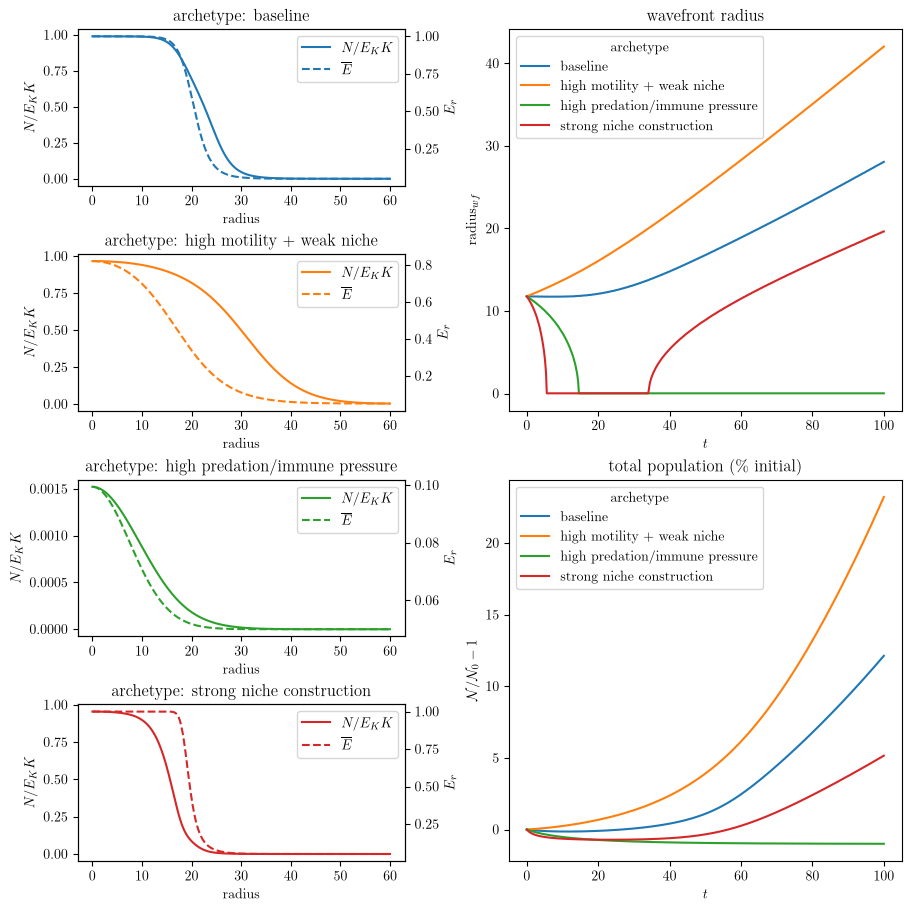

In [159]:
df = pd.DataFrame(scenario_wavefront_speed, columns = ['archetype','t','u_max','r','N','eff_area'])
df['N_init'] = config_dict['seed']['N_init']
df['N_perc'] = df['N']/df['N_init']-1
fig = plt.figure(figsize=(9, 9), constrained_layout=True)
gs = fig.add_gridspec(4, 2, width_ratios=[1, 1.2])
scenarios = [s for s, _, _ in scenario_final_profiles]
colors = sns.color_palette("tab10", n_colors=len(scenarios))
palette = dict(zip(scenarios, colors))
for i, (scenario, final_N, final_Er) in enumerate(scenario_final_profiles):
    ax = fig.add_subplot(gs[i, 0])
    ax_right = ax.twinx()

    line_n, = ax.plot(r_coords, final_N, color=palette[scenario], label="$N$")
    line_er, = ax_right.plot(
        r_coords, final_Er, color=palette[scenario], linestyle="--", label=r"$\bar{E}_{r}$"
    )

    ax.set_title("archetype: "+scenario)
    ax.set_xlabel("radius")
    ax.set_ylabel("$N/E_{K}K$")
    ax_right.set_ylabel(r"$E_{r}$")
    ax.legend([line_n, line_er], ["$N/E_{K}K$", r"$\overline{E}$"], loc="upper right")

ax_wavefront = fig.add_subplot(gs[:2, 1])
sns.lineplot(data=df, x="t", y="r", hue="archetype", ax=ax_wavefront)
ax_wavefront.set_title("wavefront radius")
ax_wavefront.set(ylabel="radius" + "$_{wf}$",xlabel="$t$")

ax_population = fig.add_subplot(gs[2:, 1])
sns.lineplot(data=df, x="t", y="N_perc", hue="archetype", ax=ax_population)
ax_population.set_title(r"total population (\% initial)")
ax_population.set(ylabel="$\\mathcal{N} / \\mathcal{N}_{0} -1$", xlabel='$t$')

plt.show()

In [94]:
df[df['archetype']=='baseline']

,archetype,t,u_max,r,N,eff_area,N_init,N_perc
0,baseline,0.0,0.318306,11.774191,100.000000,628.318531,100,1.332268e-15
1,baseline,0.2,0.317918,11.772509,99.359987,630.488784,100,-6.400132e-03
2,baseline,0.4,0.317562,11.770839,98.744231,632.640912,100,-1.255769e-02
3,baseline,0.6,0.317239,11.769195,98.152259,634.773232,100,-1.847741e-02
4,baseline,0.8,0.316958,11.767548,97.582943,636.886125,100,-2.417057e-02
...,...,...,...,...,...,...,...,...
496,baseline,99.2,15.757836,27.884783,1289.196118,1441.840383,100,1.189196e+01
497,baseline,99.4,15.757918,27.921761,1294.992685,1448.562546,100,1.194993e+01
498,baseline,99.6,15.758002,27.972352,1300.798585,1455.297623,100,1.200799e+01
499,baseline,99.8,15.758074,28.022888,1306.615537,1462.047107,100,1.206616e+01


# Hybrid PDE with retained construction benefit (derivation note, Section 10.6)
$E_r$ and $E_K$ stay place-borne fields with the notebook rate law $(1-E_j)(1-e^{-\bar b_j N})$. Heritable traits $z_1$, $z_2$ set the construction rates $b_r$, $b_K$, and $z_0$ sets motility as above. A producer keeps a share $\theta_j$ of its own construction, so it experiences $E_j^{\rm exp} = E_j + A_j(b_j(\chi_j)-\bar b_j)$ with $A_j = \theta_j(1-E_j)/\bar b_j$. With $\theta_j = 0$ the construction traits are neutral, and with $V_0 = 0$ the model reduces to the non-trait PDE. Run with the second-order system for every preset in `config_dict['presets']`. An optional low-density variance gate (derivation note, Section 10.7, version B) replaces every $V_i$ by $V_i N/(N+N_c)$, so selection, spatial sorting and the $O(V)$ corrections fade where the population is absent. It is switched by `variance_gate` and `N_c` in `hybrid_dict`. The `private_scaling` option sets the shape of the retained benefit: `'headroom'` uses $A_j = \theta_j(1-E_j)/\bar b_j$ (Section 10.6), and `'stock'` uses $A_j = \theta_j E_j(1-E_j)/\bar b_j$ (Section 10.8), which keeps the second-order closure valid while $E_j$ is small. The f-string builder below is the readable reference and has no gate; the runs use the hand-coded `HybridPDE` class, which implements the same equations and compiles in seconds. The f-string builder requires `logistic_derivs` from the builder cell of the previous section.

In [95]:
def logistic_derivs(z, k):
    """Return f-strings for L, L', ..., L^(5) of L(u) = 1/(1+exp(-k u)) at u = z."""
    L = f"(1/(1 + exp(-{k}*{z})))"
    s = f"({L}*(1 - {L}))"
    return (
        L,
        f"({k}*{s})",
        f"({k}**2*{s}*(1 - 2*{L}))",
        f"({k}**3*{s}*(1 - 6*{s}))",
        f"({k}**4*{s}*(1 - 2*{L})*(1 - 12*{s}))",
        f"({k}**5*{s}*(1 - 30*{s} + 120*{s}**2))",
    )


class HybridPDE(PDEBase):
    """Hybrid trait model with fields (N, E_r, E_k, z0, z1, z2) and the build_hybrid_rhs parameters.

    Extra optional params: 'variance_gate' (bool, default False), 'N_c' (gate half-saturation density) and
    'private_scaling': 'headroom' (default, A_j = theta_j (1 - E_j) / b_j, Section 10.6) or
    'stock' (A_j = theta_j E_j (1 - E_j) / b_j, Section 10.8).
    """

    def __init__(self, params, second_order=True, bc=None):
        super().__init__()
        for name in ("theta_r", "theta_K", "escape_public"):
            if not 0.0 <= params[name] <= 1.0:
                raise ValueError(f"{name} must lie in [0, 1]")
        if params.get("variance_gate", False) and not params.get("N_c", 0.0) > 0.0:
            raise ValueError("N_c must be positive when variance_gate is on")
        if params.get("private_scaling", "headroom") not in ("headroom", "stock"):
            raise ValueError("private_scaling must be 'headroom' or 'stock'")
        self.params = dict(params)
        self.second_order = bool(second_order)
        self.bc = {"derivative": 0} if bc is None else bc

    def evolution_rate(self, state, t=0):
        """Uncompiled evaluation of the same right-hand side (numba grid operators), as a FieldCollection."""
        rhs = self.make_evolution_rate(state, backend=get_backend("numba"))
        out = state.copy(label="evolution rate")
        out.data[:] = rhs(state.data, t)
        return out

    def make_evolution_rate(self, state, backend):
        p = self.params
        r, K, a, h, m0, eps = p["r"], p["K"], p["a"], p["h"], p["m0"], p["eps"]
        D0, br0, bK0 = p["D0"], p["br0"], p["bK0"]
        k0, k1, k2 = p["k0"], p["k1"], p["k2"]
        V0, V1, V2 = p["V0"], p["V1"], p["V2"]
        theta_r, theta_K = p["theta_r"], p["theta_K"]
        w = 1.0 - p["escape_public"]
        N_eps = p["N_eps"]
        gate_on = bool(p.get("variance_gate", False))
        N_c = float(p.get("N_c", 1.0))
        stock = p.get("private_scaling", "headroom") == "stock"

        grid = state.grid
        ops = {"backend": backend, "dtype": state.dtype}
        laplace = grid.make_operator("laplace", bc=self.bc, **ops)
        gradient = grid.make_operator("gradient", bc=self.bc, **ops)
        gradient_squared = grid.make_operator("gradient_squared", bc=self.bc, **ops)

        def ecology(N, E_r, E_k):
            """Shared ecology terms at the field values (H, eta, kappa, lambda, crowding, g)."""
            H = a / (1.0 + a * h * N)
            q = 1.0 + eps * 0.5 * (E_r + E_k)
            meff = m0 / q
            eta = m0 * eps * H / (2.0 * q**2)              # -0.5 m_E H
            kap = m0 * eps**2 * H / (2.0 * q**3)           # 0.25 m_EE H
            lam = -3.0 * m0 * eps**3 * H / (4.0 * q**4)    # 0.125 m_EEE H
            crowd = 1.0 - N / (K * E_k)
            g = r * E_r * crowd - meff * H
            Gr = r * crowd + w * eta                       # dG/dE_r^exp
            GK = r * E_r * N / (K * E_k**2) + w * eta      # dG/dE_K^exp
            return g, Gr, GK, kap, lam

        if backend.name == "numba":
            ecology = backend.compile_function(ecology)

        def pde_rhs_leading(state_data, t=0):
            N, E_r, E_k = state_data[0], state_data[1], state_data[2]
            if gate_on:
                gam = N / (N + N_c)                        # variance gate gamma(N)
            else:
                gam = np.ones_like(N)
            z0, z1, z2 = state_data[3], state_data[4], state_data[5]
            lapN, lap0, lap1, lap2 = (laplace(N), laplace(z0),
                                      laplace(z1), laplace(z2))
            gN, g1, g2 = gradient(N), gradient(z1), gradient(z2)

            # sigmoid L(k z) and derivatives, computed once per grid point
            L0 = 1.0 / (1.0 + np.exp(-k0 * z0)); s0 = L0 * (1.0 - L0)
            L1 = 1.0 / (1.0 + np.exp(-k1 * z1)); s1 = L1 * (1.0 - L1)
            L2 = 1.0 / (1.0 + np.exp(-k2 * z2)); s2 = L2 * (1.0 - L2)
            D, Dp = D0 * L0, D0 * k0 * s0
            br, brp = br0 * L1, br0 * k1 * s1
            bK, bKp = bK0 * L2, bK0 * k2 * s2

            g, Gr, GK, kap, lam = ecology(N, E_r, E_k)
            # retained-benefit factor A_j: headroom (1 - E_j) or stock E_j (1 - E_j)
            if stock:
                Ar = theta_r * E_r * (1.0 - E_r) / br
                AK = theta_K * E_k * (1.0 - E_k) / bK
            else:
                Ar = theta_r * (1.0 - E_r) / br
                AK = theta_K * (1.0 - E_k) / bK
            invN = 1.0 / (N + N_eps)

            out = np.empty_like(state_data)
            out[0] = D * lapN + N * g
            out[1] = (1.0 - E_r) * (1.0 - np.exp(-br * N))
            out[2] = (1.0 - E_k) * (1.0 - np.exp(-bK * N))
            # leading-order sorting keeps only V0 D' lap(N)/N; gated: V0 D' lap(gamma N)/N
            if gate_on:
                sort0 = V0 * Dp * laplace(gam * N) * invN
            else:
                sort0 = V0 * Dp * lapN * invN
            out[3] = D * (lap0 + 2.0 * np.sum(gN * gradient(z0), axis=0) * invN) + sort0
            out[4] = gam * V1 * Ar * brp * Gr + D * (lap1 + 2.0 * np.sum(gN * g1, axis=0) * invN)
            out[5] = gam * V2 * AK * bKp * GK + D * (lap2 + 2.0 * np.sum(gN * g2, axis=0) * invN)
            return out

        def pde_rhs_second(state_data, t=0):
            N, E_r, E_k = state_data[0], state_data[1], state_data[2]
            if gate_on:
                gam = N / (N + N_c)                        # variance gate gamma(N)
            else:
                gam = np.ones_like(N)
            V0g, V1g, V2g = V0 * gam, V1 * gam, V2 * gam   # gated variances (equal to V_i when off)
            z0, z1, z2 = state_data[3], state_data[4], state_data[5]
            lapN, lap0, lap1, lap2 = (laplace(N), laplace(z0),
                                      laplace(z1), laplace(z2))
            gN, g0 = gradient(N), gradient(z0)
            g1, g2 = gradient(z1), gradient(z2)
            gsq0 = gradient_squared(z0)

            # sigmoid L(k z) and derivatives up to L^(5), computed once per grid point
            L0 = 1.0 / (1.0 + np.exp(-k0 * z0)); s0 = L0 * (1.0 - L0)
            L1 = 1.0 / (1.0 + np.exp(-k1 * z1)); s1 = L1 * (1.0 - L1)
            L2 = 1.0 / (1.0 + np.exp(-k2 * z2)); s2 = L2 * (1.0 - L2)
            D = D0 * L0
            Dp = D0 * k0 * s0
            Dpp = D0 * k0**2 * s0 * (1.0 - 2.0 * L0)
            Dppp = D0 * k0**3 * s0 * (1.0 - 6.0 * s0)
            Dpppp = D0 * k0**4 * s0 * (1.0 - 2.0 * L0) * (1.0 - 12.0 * s0)
            Dppppp = D0 * k0**5 * s0 * (1.0 - 30.0 * s0 + 120.0 * s0**2)
            br = br0 * L1
            brp = br0 * k1 * s1
            brpp = br0 * k1**2 * s1 * (1.0 - 2.0 * L1)
            brppp = br0 * k1**3 * s1 * (1.0 - 6.0 * s1)
            bK = bK0 * L2
            bKp = bK0 * k2 * s2
            bKpp = bK0 * k2**2 * s2 * (1.0 - 2.0 * L2)
            bKppp = bK0 * k2**3 * s2 * (1.0 - 6.0 * s2)

            # O(V) mean coefficients
            bbr = br + 0.5 * V1g * brpp
            bbK = bK + 0.5 * V2g * bKpp
            Db = D + 0.5 * V0g * Dpp
            Dbp = Dp + 0.5 * V0g * Dppp
            Dbpp = Dpp + 0.5 * V0g * Dpppp
            Dbppp = Dppp + 0.5 * V0g * Dppppp

            g, Gr, GK, kap, lam = ecology(N, E_r, E_k)
            # retained-benefit factor A_j: headroom (1 - E_j) or stock E_j (1 - E_j)
            if stock:
                Ar = theta_r * E_r * (1.0 - E_r) / bbr
                AK = theta_K * E_k * (1.0 - E_k) / bbK
            else:
                Ar = theta_r * (1.0 - E_r) / bbr
                AK = theta_K * (1.0 - E_k) / bbK
            invN = 1.0 / (N + N_eps)

            # derivatives of G_j with respect to the experienced niches
            dGr_r = -(w**2) * kap
            d2Gr_r = -(w**3) * lam
            d2Gr_K = -2.0 * r * N / (K * E_k**3) - w**3 * lam
            dGK_K = -2.0 * r * E_r * N / (K * E_k**3) - w**2 * kap
            d2GK_K = 6.0 * r * E_r * N / (K * E_k**4) - w**3 * lam
            d2GK_r = -(w**3) * lam

            # mean fitness (Jensen term) and full selection terms <dG/dchi_j> to O(V)
            Gbar = g + 0.5 * (V1g * Ar**2 * brp**2 * dGr_r + V2g * AK**2 * bKp**2 * dGK_K)
            sel1 = Ar * (brp * Gr
                         + V1g * (0.5 * brppp * Gr + Ar * brp * brpp * dGr_r + 0.5 * Ar**2 * brp**3 * d2Gr_r)
                         + 0.5 * V2g * AK**2 * bKp**2 * brp * d2Gr_K)
            sel2 = AK * (bKp * GK
                         + V2g * (0.5 * bKppp * GK + AK * bKp * bKpp * dGK_K + 0.5 * AK**2 * bKp**3 * d2GK_K)
                         + 0.5 * V1g * Ar**2 * brp**2 * bKp * d2GK_r)

            dot_N0 = np.sum(gN * g0, axis=0)
            out = np.empty_like(state_data)
            out[1] = (1.0 - E_r) * (1.0 - np.exp(-bbr * N))
            out[2] = (1.0 - E_k) * (1.0 - np.exp(-bbK * N))
            if gate_on:
                # Dbar now depends on N through gamma, so use the divergence forms:
                # lap(Dbar N), transport with grad(Dbar), sorting (1/N) lap(N V0g Dbar')
                gDb = gradient(Db)
                out[0] = laplace(Db * N) + N * Gbar
                out[3] = (Db * lap0 + 2.0 * Db * dot_N0 * invN + 2.0 * np.sum(gDb * g0, axis=0)
                          + laplace(N * V0g * Dbp) * invN)
                out[4] = (V1g * sel1 + Db * lap1 + 2.0 * Db * np.sum(gN * g1, axis=0) * invN
                          + 2.0 * np.sum(gDb * g1, axis=0))
                out[5] = (V2g * sel2 + Db * lap2 + 2.0 * Db * np.sum(gN * g2, axis=0) * invN
                          + 2.0 * np.sum(gDb * g2, axis=0))
            else:
                out[0] = (Db * lapN + 2.0 * Dbp * dot_N0
                          + N * (Dbp * lap0 + Dbpp * gsq0) + N * Gbar)
                out[3] = (Db * lap0 + 2.0 * Db * dot_N0 * invN + 2.0 * Dbp * np.sum(g0 * g0, axis=0)
                          + V0 * (Dbp * lapN * invN + 2.0 * Dbpp * dot_N0 * invN
                                  + Dbpp * lap0 + Dbppp * gsq0))
                out[4] = (V1 * sel1 + Db * lap1 + 2.0 * Db * np.sum(gN * g1, axis=0) * invN
                          + 2.0 * Dbp * np.sum(g0 * g1, axis=0))
                out[5] = (V2 * sel2 + Db * lap2 + 2.0 * Db * np.sum(gN * g2, axis=0) * invN
                          + 2.0 * Dbp * np.sum(g0 * g2, axis=0))
            return out

        return pde_rhs_second if self.second_order else pde_rhs_leading

In [131]:
# Hybrid-model settings with no counterpart in config_dict. Values are placeholders for
# exploration, not calibrated estimates. The PDEs are second-order HybridPDE instances (cell above),
# built per preset in the run cell below.
hybrid_dict = {
    'k': (4, 4, 4),            # sigmoid steepness for z0 (motility), z1 (b_r), z2 (b_K)
    'V': (0.01, 0.01, 0.01),   # standing trait variances V0, V1, V2 (low-variance closure)
    'D_max_factor': 2.0,       # plateau D0 = D_max_factor * D, so the run starts at the preset D
    'b_max_factor': 2.0,       # plateaus b_j0 = b_max_factor * b_j, so the run starts at the preset b_j
    'theta': (0.5, 0.5),       # retained shares theta_r, theta_K; (0, 0) gives the neutral hybrid
    'escape_public': 0.0,      # omega; 0.0 means escape follows the experienced niche
    'N_eps': 1e-3,             # regulariser for 1/N in the trait equations
    'variance_gate': True,     # Section 10.7 version B: V_i -> V_i * N/(N + N_c) everywhere
    'N_c': 1e-3,               # gate half-saturation density (model units of N); keep well below the seed
    'private_scaling': 'stock',  # 'headroom' (Section 10.6) or 'stock' (Section 10.8, closure-safe at low E_j)
}


def build_hybrid_params(preset, traits):
    """Map a config_dict preset onto HybridPDE parameters.

    build_hybrid_rhs has no gate: drop 'variance_gate' and 'N_c' before passing these to it.
    """
    k0, k1, k2 = traits['k']
    V0, V1, V2 = traits['V']
    theta_r, theta_K = traits['theta']
    return dict(
        r=preset['r'], K=preset['K'], a=preset['a'], h=preset['h'], m0=preset['m0'],
        eps=preset['escape'],
        D0=traits['D_max_factor'] * preset['D'],
        br0=traits['b_max_factor'] * preset['b_r'], bK0=traits['b_max_factor'] * preset['b_k'],
        k0=k0, k1=k1, k2=k2, V0=V0, V1=V1, V2=V2,
        theta_r=theta_r, theta_K=theta_K,
        escape_public=traits['escape_public'], N_eps=traits['N_eps'],
        variance_gate=traits['variance_gate'], N_c=traits['N_c'],
        private_scaling=traits['private_scaling'],
    )


def build_hybrid_state(config, preset, params):
    """Initial N from build_initial_N; E fields at E_r0, E_k0; uniform z so D, b_r, b_K start at the preset values."""
    u_field, r_coords = build_initial_N(config)
    grid = u_field.grid

    def z_for(value, plateau, k):
        p = value / plateau
        return np.log(p / (1 - p)) / k

    z_init = (
        z_for(preset['D'], params['D0'], params['k0']),
        z_for(preset['b_r'], params['br0'], params['k1']),
        z_for(preset['b_k'], params['bK0'], params['k2']),
    )
    Er_field = ScalarField(grid, data=np.full_like(u_field.data, preset['E_r0']), label="E_r")
    Ek_field = ScalarField(grid, data=np.full_like(u_field.data, preset['E_k0']), label="E_k")
    z_fields = [ScalarField(grid, data=np.full_like(u_field.data, z), label=f"z{i}")
                for i, z in enumerate(z_init)]
    return FieldCollection([u_field, Er_field, Ek_field] + z_fields), r_coords


def sigmoid_value(z, k, plateau):
    """plateau*L(z) on the grid (leading-order value, no variance correction)."""
    return plateau / (1 + np.exp(-k * z))

In [ ]:
# Run every preset with the second-order hybrid system.
# A HybridPDE is built per preset (parameters differ), so each preset compiles with numba (a few seconds).
hybrid_scenario_params = {}
hybrid_scenario_wavefront_speeds = []
hybrid_scenario_final_profiles = []
for preset_name, preset_config in config_dict['presets'].items():
    print(f"Running hybrid model (second order) for preset: {preset_name}")
    params = build_hybrid_params(preset_config, hybrid_dict)

    hybrid_scenario_params[preset_name] = params
    print(params)
    pde_system = HybridPDE(params, second_order=True, bc=config_dict['bcs'])
    state, r_coords = build_hybrid_state(config_dict, preset_config, params)
    e_field_init = state[2].data[0]
    storage = MemoryStorage()
    pde_system.solve(
        state,
        t_range=config_dict['integration']['t_max'],
        dt=config_dict['integration']['dt'],
        tracker=['progress', storage.tracker(config_dict['analysis']['tracker_time'])],
        adaptive=True, backend='numba')
    for t_idx, time in enumerate(storage.times):
        curr_u = storage[t_idx][0].data
        e_field = storage[t_idx][2].data
        r_val, idx = compute_wavefront_idx(config_dict['analysis'], curr_u, r_coords,e_field)
        hybrid_scenario_wavefront_speeds.append((preset_name, time, r_val, rolling_area(e_field_init*curr_u/e_field, r_coords)[-1],compute_participation_area(storage[t_idx][0])))
    final = storage[-1]
    final_Er = final[1].data
    final_Ek = final[2].data
    final_N = final[0].data
    final_D = sigmoid_value(final[3].data, params['k0'], params['D0'])
    final_br = sigmoid_value(final[4].data, params['k1'], params['br0'])
    final_bK = sigmoid_value(final[5].data, params['k2'], params['bK0'])
    print(np.max(final_D), np.min(final_D))
    final_area = rolling_area(final[0].data, r_coords)[-1]
    hybrid_scenario_final_profiles.append((preset_name,final_N,2*np.pi*r_coords*np.gradient(r_coords)*final[0].data*(final_D/(params['D0']/2)-1)/final_area, 2*np.pi*r_coords*np.gradient(r_coords)*final[0].data*(final_br/(params['br0']/2)-1)/final_area, 2*np.pi*r_coords*np.gradient(r_coords)*final[0].data*(final_bK/(params['bK0']/2)-1)/final_area))

Running hybrid model (second order) for preset: baseline
{'r': 0.5, 'K': np.float64(15.915303324174578), 'a': 0.03, 'h': 0.05, 'm0': 0.25, 'eps': 0.5, 'D0': 0.7, 'br0': 0.03, 'bK0': 0.03, 'k0': 4, 'k1': 4, 'k2': 4, 'V0': 0.01, 'V1': 0.01, 'V2': 0.01, 'theta_r': 0.5, 'theta_K': 0.5, 'escape_public': 0.0, 'N_eps': 0.001, 'variance_gate': True, 'N_c': 0.001, 'private_scaling': 'stock'}


Initializing:   0%|          | 0/100.0 [00:00<?, ?it/s]

100%|██████████| 100.0/100.0 [00:17<00:00,  5.75it/s]        


0.3876195991400958 0.341646116642039
Running hybrid model (second order) for preset: high motility + weak niche
{'r': 0.95, 'K': np.float64(15.915303324174578), 'a': 0.03, 'h': 0.1, 'm0': 0.25, 'eps': 0.75, 'D0': 1.8, 'br0': 0.01, 'bK0': 0.01, 'k0': 4, 'k1': 4, 'k2': 4, 'V0': 0.01, 'V1': 0.01, 'V2': 0.01, 'theta_r': 0.5, 'theta_K': 0.5, 'escape_public': 0.0, 'N_eps': 0.001, 'variance_gate': True, 'N_c': 0.001, 'private_scaling': 'stock'}


100%|██████████| 100.0/100.0 [00:15<00:00,  6.44it/s]        


0.9866375236716053 0.8651039054858285
Running hybrid model (second order) for preset: high predation/immune pressure
{'r': 0.5, 'K': np.float64(15.915303324174578), 'a': 0.2, 'h': 0.02, 'm0': 0.4, 'eps': 0.1, 'D0': 0.7, 'br0': 0.02, 'bK0': 0.02, 'k0': 4, 'k1': 4, 'k2': 4, 'V0': 0.01, 'V1': 0.01, 'V2': 0.01, 'theta_r': 0.5, 'theta_K': 0.5, 'escape_public': 0.0, 'N_eps': 0.001, 'variance_gate': True, 'N_c': 0.001, 'private_scaling': 'stock'}


100%|██████████| 100.0/100.0 [00:14<00:00,  7.07it/s]        


0.356448280257167 0.34035466617171306
Running hybrid model (second order) for preset: strong niche construction
{'r': 0.13, 'K': np.float64(15.915303324174578), 'a': 0.03, 'h': 0.04, 'm0': 0.25, 'eps': 0.5, 'D0': 0.3, 'br0': 0.2, 'bK0': 0.2, 'k0': 4, 'k1': 4, 'k2': 4, 'V0': 0.01, 'V1': 0.01, 'V2': 0.01, 'theta_r': 0.5, 'theta_K': 0.5, 'escape_public': 0.0, 'N_eps': 0.001, 'variance_gate': True, 'N_c': 0.001, 'private_scaling': 'stock'}


100%|██████████| 100.0/100.0 [00:15<00:00,  6.42it/s]        

0.16720774761743132 0.14771164813653576


In [133]:
# Baseline second-order hybrid run, keeping D, b_r and b_K over r and t for the heatmaps below.
# Stored every heatmap_tracker_time (coarser than config_dict['analysis']['tracker_time']).
heatmap_tracker_time = 1.0
heatmap_preset_name = 'baseline'
heatmap_preset = config_dict['presets'][heatmap_preset_name]
heatmap_params = build_hybrid_params(heatmap_preset, hybrid_dict)
heatmap_pde = HybridPDE(heatmap_params, second_order=True, bc=config_dict['bcs'])
print(heatmap_params)
heatmap_state, r_coords = build_hybrid_state(config_dict, heatmap_preset, heatmap_params)
heatmap_storage = MemoryStorage()
heatmap_pde.solve(
    heatmap_state,
    t_range=config_dict['integration']['t_max'],
    dt=config_dict['integration']['dt'],
    tracker=['progress', heatmap_storage.tracker(heatmap_tracker_time)],
    adaptive=True, backend='numba')

heatmap_times = np.array(heatmap_storage.times)
# arrays of shape (n_times, n_radii)
heatmap_D = np.array([2*np.pi*r_coords*s[0].data*np.gradient(r_coords)*(sigmoid_value(s[3].data, heatmap_params['k0'], heatmap_params['D0'])/heatmap_preset['D']-1)/(rolling_area(s[0].data,r_coords)[-1]) for s in heatmap_storage])
heatmap_br = np.array([2*np.pi*r_coords*s[0].data*np.gradient(r_coords)*(sigmoid_value(s[4].data, heatmap_params['k1'], heatmap_params['br0'])/heatmap_preset['b_r']-1)/(rolling_area(s[0].data,r_coords)[-1]) for s in heatmap_storage])
heatmap_bK = np.array([2*np.pi*r_coords*s[0].data*np.gradient(r_coords)*(sigmoid_value(s[5].data, heatmap_params['k2'], heatmap_params['bK0'])/heatmap_preset['b_k']-1)/(rolling_area(s[0].data,r_coords)[-1]) for s in heatmap_storage])
heatmap_N = np.array([s[0].data for s in heatmap_storage])


{'r': 0.5, 'K': np.float64(15.915303324174578), 'a': 0.03, 'h': 0.05, 'm0': 0.25, 'eps': 0.5, 'D0': 0.7, 'br0': 0.03, 'bK0': 0.03, 'k0': 4, 'k1': 4, 'k2': 4, 'V0': 0.01, 'V1': 0.01, 'V2': 0.01, 'theta_r': 0.5, 'theta_K': 0.5, 'escape_public': 0.0, 'N_eps': 0.001, 'variance_gate': True, 'N_c': 0.001, 'private_scaling': 'stock'}


100%|██████████| 100.0/100.0 [00:14<00:00,  6.97it/s]        


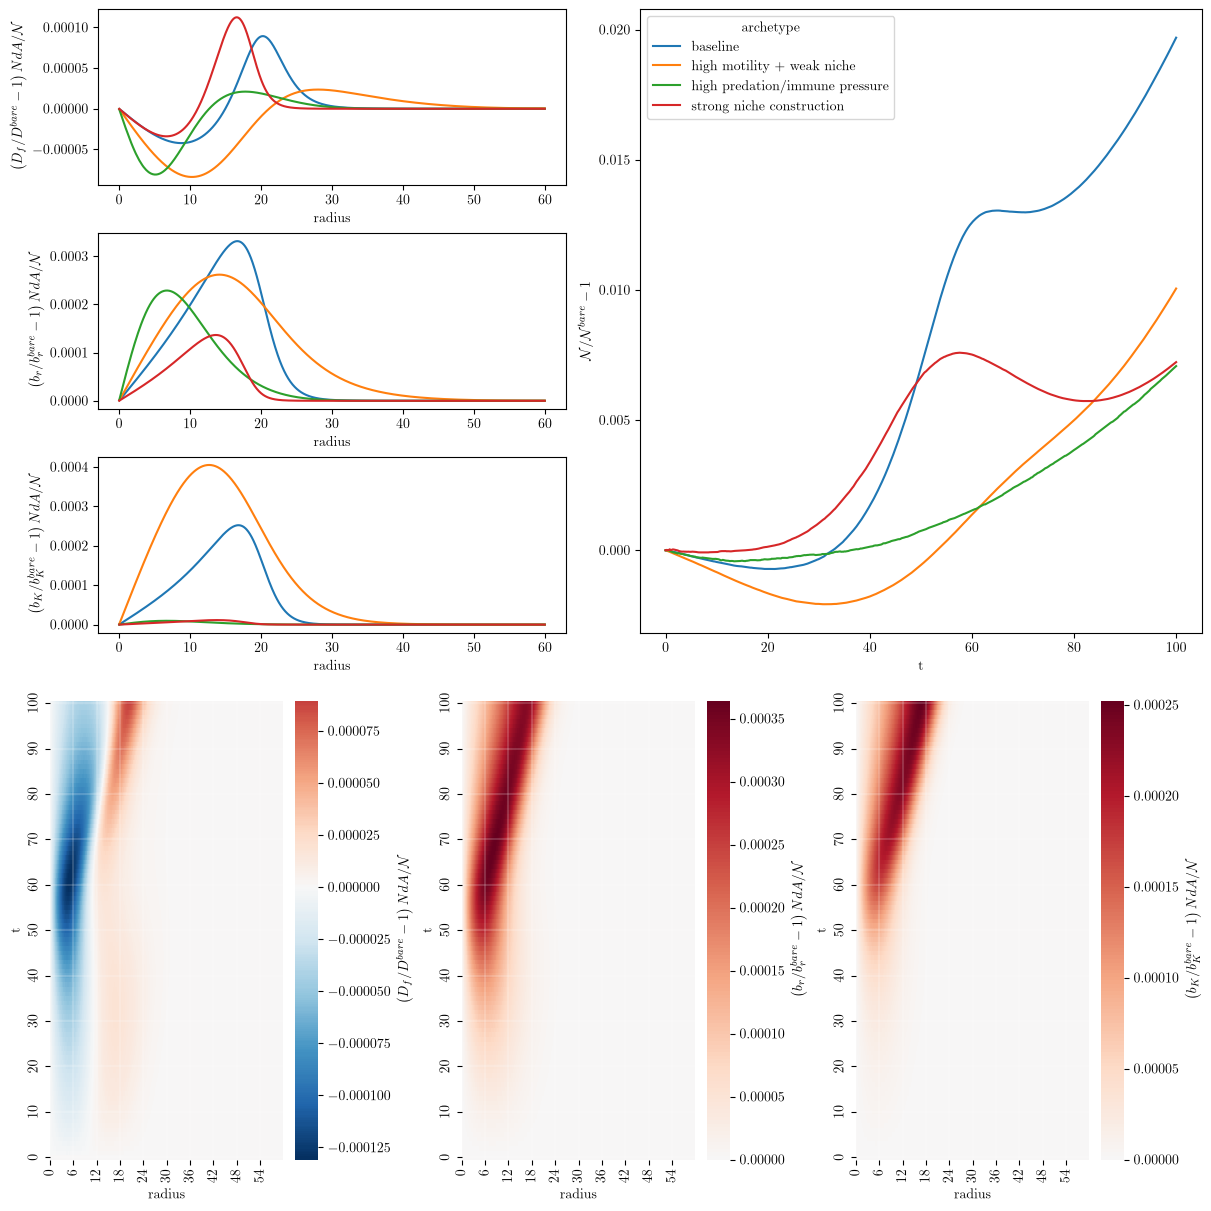

In [156]:
# Second-order hybrid runs, 4 x 2 grid of equal panels.
# Left column: final N and the N-weighted relative change in D, b_r, b_K for all presets.
# Right column: total population relative to the bare PDE, then baseline D, b_r, b_K heatmaps over r and t.
# A narrow third grid column holds the heatmap colorbars so all eight panels keep the same size.
df_hybrid = pd.DataFrame(hybrid_scenario_wavefront_speeds, columns=['archetype', 't', 'r', 'N', 'eff_area'])
df_hybrid['N_init'] = config_dict['seed']['N_init']
df_hybrid['N_perc'] = df_hybrid['N'] / df_hybrid['N_init']
df_hybrid = df_hybrid.merge(df.rename(columns = {'r':'base_r','N_perc':'base_N_perc','N':'base_N'}), how='left', on = ['archetype','t'])
df_hybrid['r_perc_base'] = 100*(df_hybrid['r']/df_hybrid['base_r']-1)
df_hybrid['N_perc_base'] = df_hybrid['N']/df_hybrid['base_N'] -1 
hybrid_scenarios = [profile[0] for profile in hybrid_scenario_final_profiles]
hybrid_palette = dict(zip(hybrid_scenarios, sns.color_palette("tab10", n_colors=len(hybrid_scenarios))))
fig = plt.figure(figsize=(11, 12), constrained_layout=True)
gs = fig.add_gridspec(4, 3, width_ratios=[1, 1, 0.04])
profile_panels = [
    ((1,), ("$N$",)),
    ((2,), ("$\\left(D_f/D^{bare}-1 \\right)NdA/\\mathcal{N}$",)),
    ((3,), ("$\\left( b_{r}/b_{r}^{bare}-1 \\right)NdA/\\mathcal{N}$",)),
    ((4,), ("$\\left( b_{K}/b_{K}^{bare}-1 \\right)NdA/\\mathcal{N}$",))#
]
for row, (col_idxs, labels) in enumerate(profile_panels):
    ax = fig.add_subplot(gs[row, 0])
    for profile in hybrid_scenario_final_profiles:
        for col_idx, label, style in zip(col_idxs, labels, ("-", "--")):
            ax.plot(r_coords, profile[col_idx], color=hybrid_palette[profile[0]], linestyle=style)
    ax.set_xlabel("radius")
    ax.set_ylabel(", ".join(labels))
    if len(col_idxs) > 1:
        # line style legend only; preset colours are in the wavefront legend
        style_handles = [plt.Line2D([], [], color="0.3", linestyle=style) for style in ("-", "--")]
        ax.legend(style_handles, labels, loc="center right", fontsize="small")

ax_population = fig.add_subplot(gs[0, 1])
sns.lineplot(data=df_hybrid, x="t", y="N_perc_base", hue="archetype", palette=hybrid_palette, ax=ax_population)
ax_population.set_ylabel(r"$\mathcal{N} / \mathcal{N}^{bare} -1 $")
ax_population.set_xlabel("$t$")
heatmap_panels = [
    (heatmap_D, heatmap_preset['D'], "$\\left(D_f/D^{bare}-1 \\right)NdA/\\mathcal{N}$"),
    (heatmap_br, heatmap_preset['b_r'], "$\\left( b_{r}/b_{r}^{bare}-1 \\right)NdA/\\mathcal{N}$"),
    (heatmap_bK, heatmap_preset['b_k'], "$\\left( b_{K}/b_{K}^{bare}-1 \\right)NdA/\\mathcal{N}$"),
]
for row, (values, base_value, label) in enumerate(heatmap_panels, start=1):
    ax = fig.add_subplot(gs[row, 1])
    cbar_ax = fig.add_subplot(gs[row, 2])
    rel = pd.DataFrame(values,
                       index=np.round(heatmap_times, 0), columns=np.round(r_coords, 3))
    sns.heatmap(
        rel, cmap="RdBu_r", center=0, ax=ax, cbar_ax=cbar_ax,
        xticklabels=100, yticklabels=10,
        cbar_kws={"label": label}
    )
    ax.set_xticklabels([f"{float(label.get_text()):.0f}" for label in ax.get_xticklabels()])
    ax.set_yticklabels([f"{float(label.get_text()):.0f}" for label in ax.get_yticklabels()])
    ax.grid(which="major", color="white", linewidth=0.25)
    ax.tick_params(which="minor", bottom=False, left=False)
    ax.invert_yaxis()  # t increases upward
    ax.tick_params(axis="x", labelrotation=90)
    ax.set_xlabel("radius")
    ax.set_ylabel("t")
plt.show()

In [108]:
df_late = df_hybrid.loc[df_hybrid["t"] >= 60]

slopes = {
    archetype: {
        column: np.polyfit(group["t"], group[column], 1)[0]
        for column in ("base_r", "r")
    }
    for archetype, group in df_late.groupby("archetype")
}

slopes

{'baseline': {'base_r': np.float64(0.2296729340318591),
  'r': np.float64(0.23776141714578955)},
 'high motility + weak niche': {'base_r': np.float64(0.3441744855670987),
  'r': np.float64(0.35088771567987437)},
 'high predation/immune pressure': {'base_r': np.float64(-1.210906176859742e-19),
  'r': np.float64(-1.210906176859742e-19)},
 'strong niche construction': {'base_r': np.float64(0.20221046291050596),
  'r': np.float64(0.20426446253448613)}}

In [79]:
# for each scenario, pull the D and b_r fields, couple them to r_coords, then plot joint plot
profile_frames = []
for archetype, D_profile, br_profile, bK_profile in hybrid_scenario_final_profiles:
    profile_frames.append(pd.DataFrame({
        'archetype': str(archetype),
        'r': r_coords,
        'D': D_profile,
        'b_r': br_profile,
        'b_K': bK_profile,
    }))
df_profiles = pd.concat(profile_frames, ignore_index=True)
df_profiles.head()

,archetype,r,D,b_r,b_K
0,baseline,0.03,-0.017749,0.043629,0.007521
1,baseline,0.09,-0.053244,0.130887,0.022562
2,baseline,0.15,-0.088733,0.218147,0.037605
3,baseline,0.21,-0.124210,0.305412,0.052650
4,baseline,0.27,-0.159672,0.392684,0.067699


In [116]:
hybrid_scenario_final_profiles[0][1].mean()

np.float64(0.06984917472430102)